# 2026 — Capstone: a Tiny Frontier-Style Language Model

This notebook assembles the pieces of a 2026 open-weight frontier LLM into one small model and trains it next to a 2019-style GPT-2 block.

**Blueprint**, taken from published 2026 designs:
- **Qwen3.5** (model card): `15 × (3 × (Gated DeltaNet → MoE) → 1 × (Gated Attention → MoE))`, with 512 experts (10 routed + 1 shared active per token) and multi-token prediction
- **DeepSeek-V4** (arXiv 2606.19348): MoE with a shared expert and bias-based ("auxiliary-loss-free") load balancing, MTP depth 1, the Muon optimizer, and hybrid long-context attention (notebook 78)

| component | notebook | used here |
|---|---|---|
| Gated DeltaNet (linear memory, delta rule) | 49 | 3 of every 4 layers |
| Gated attention + RoPE + QK-norm + GQA | 50, 53 | 1 of every 4 layers |
| Fine-grained MoE + shared expert, aux-loss-free balancing | 44 | after every mixer |
| Multi-token prediction | 47 | depth 1, weight 0.3 |
| Muon for hidden matrices, AdamW for the rest | 53 | yes |
| RMSNorm, pre-norm, SwiGLU experts | 53 | yes |

Not included, to keep it small: MLA/CSA/HCA (67, 78), mHC (76), Engram (77), and post-training (SFT, RL from notebooks 58 and 69).

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")
CTX = 64

290,321 characters, vocab 31


In [3]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

def rope(x, base=10000.0):
    T, d = x.shape[-2], x.shape[-1]
    inv = 1.0 / base ** (torch.arange(0, d, 2, device=x.device).float() / d)
    ang = torch.arange(T, device=x.device).float()[:, None] * inv
    x1, x2 = x[..., ::2], x[..., 1::2]
    return torch.stack([x1 * ang.cos() - x2 * ang.sin(), x1 * ang.sin() + x2 * ang.cos()], -1).flatten(-2)

class GatedDeltaNet(nn.Module):
    """S_t = a_t S_{t-1} (I - b_t k_t k_t^T) + b_t v_t k_t^T,  o_t = S_t q_t  (recurrent form), with an output gate."""
    def __init__(self, d, heads=2):
        super().__init__()
        self.h, self.dk = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.conv = nn.Conv1d(3 * d, 3 * d, 4, groups=3 * d, padding=3)               # short causal conv on q, k, v
        self.ab = nn.Linear(d, 2 * heads)                                            # forget gate a_t and write strength b_t
        self.gate, self.onorm, self.o = nn.Linear(d, d, bias=False), RMSNorm(self.dk), nn.Linear(d, d, bias=False)
    def forward(self, x):
        B, T, D = x.shape
        qkv = F.silu(self.conv(self.qkv(x).transpose(1, 2))[..., :T].transpose(1, 2))
        q, k, v = (t.view(B, T, self.h, self.dk) for t in qkv.chunk(3, -1))
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        a, b = self.ab(x).chunk(2, -1); a = torch.sigmoid(a + 3.0); b = torch.sigmoid(b)
        S = torch.zeros(B, self.h, self.dk, self.dk, device=x.device); outs = []
        for t in range(T):
            kt, vt = k[:, t], v[:, t]
            S = a[:, t, :, None, None] * S
            S = S + b[:, t, :, None, None] * (vt - (S @ kt.unsqueeze(-1)).squeeze(-1)).unsqueeze(-1) * kt.unsqueeze(-2)
            outs.append((S @ q[:, t].unsqueeze(-1)).squeeze(-1))
        o = self.onorm(torch.stack(outs, 1)).reshape(B, T, D)
        return self.o(o * torch.sigmoid(self.gate(x)))

class GatedAttention(nn.Module):
    """GQA with RoPE, QK-norm and the elementwise sigmoid output gate (position G1)."""
    def __init__(self, d, heads=4, kv_heads=2):
        super().__init__()
        self.h, self.kvh, self.dh = heads, kv_heads, d // heads
        self.wq, self.wkv = nn.Linear(d, d, bias=False), nn.Linear(d, 2 * kv_heads * self.dh, bias=False)
        self.qn, self.kn = RMSNorm(self.dh), RMSNorm(self.dh)
        self.gate, self.o = nn.Linear(d, d, bias=True), nn.Linear(d, d, bias=False)
    def forward(self, x):
        B, T, D = x.shape
        q = self.wq(x).view(B, T, self.h, self.dh).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.kvh, self.dh).permute(2, 0, 3, 1, 4)
        q, k = rope(self.qn(q)), rope(self.kn(k))
        k, v = k.repeat_interleave(self.h // self.kvh, 1), v.repeat_interleave(self.h // self.kvh, 1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D)
        return self.o(y * torch.sigmoid(self.gate(x)))

class MoE(nn.Module):
    """1 shared + E routed SwiGLU experts, top-k. Load balancing without an auxiliary loss: a per-expert bias is added
    to the routing scores for *selection only* and nudged after each step toward an even load (DeepSeek-V3 style)."""
    def __init__(self, d, E=8, k=2, hidden=64):
        super().__init__()
        self.E, self.k = E, k
        self.router = nn.Linear(d, E, bias=False)
        self.w1 = nn.Parameter(torch.randn(E, d, 2 * hidden) / math.sqrt(d)); self.w2 = nn.Parameter(torch.randn(E, hidden, d) / math.sqrt(hidden))
        self.shared = nn.Sequential(nn.Linear(d, 2 * hidden, bias=False), nn.Identity(), nn.Linear(hidden, d, bias=False))
        self.register_buffer("bias", torch.zeros(E)); self.load = torch.zeros(E)
    def expert(self, x, w1, w2):
        a, b = (x @ w1).chunk(2, -1); return (F.silu(a) * b) @ w2
    def forward(self, x):
        shp = x.shape; x = x.reshape(-1, shp[-1])
        scores = torch.sigmoid(self.router(x))                                       # affinity (V3: sigmoid; V4: sqrt-softplus)
        top = (scores + self.bias).topk(self.k, -1).indices                          # bias affects selection only
        gates = scores.gather(1, top); gates = gates / gates.sum(-1, keepdim=True)
        out = torch.zeros_like(x)
        for e in range(self.E):
            tok, slot = torch.where(top == e)
            if len(tok): out.index_add_(0, tok, self.expert(x[tok], self.w1[e], self.w2[e]) * gates[tok, slot, None])
        a, b = self.shared[0](x).chunk(2, -1)
        out = out + self.shared[2](F.silu(a) * b)
        self.load = torch.bincount(top.flatten(), minlength=self.E).float().detach()
        return out.view(shp)
    @torch.no_grad()
    def update_bias(self, speed=1e-3 * 30):                                          # (faster than the paper's 1e-3 for a short run)
        self.bias += speed * torch.sign(self.load.mean() - self.load).to(self.bias.device)

class FrontierLM(nn.Module):
    def __init__(self, d=96, groups=1, mtp=True):
        super().__init__()
        self.tok = nn.Embedding(V, d)
        mixers = [m for _ in range(groups) for m in [GatedDeltaNet(d), GatedDeltaNet(d), GatedDeltaNet(d), GatedAttention(d)]]
        self.mixers = nn.ModuleList(mixers); self.moes = nn.ModuleList([MoE(d) for _ in mixers])
        self.n1 = nn.ModuleList([RMSNorm(d) for _ in mixers]); self.n2 = nn.ModuleList([RMSNorm(d) for _ in mixers])
        self.ln, self.head = RMSNorm(d), nn.Linear(d, V, bias=False)
        if mtp:
            self.mtp_nh, self.mtp_ne, self.mtp_proj = RMSNorm(d), RMSNorm(d), nn.Linear(2 * d, d, bias=False)
            self.mtp_mixer, self.mtp_moe, self.mtp_n1, self.mtp_n2 = GatedAttention(d), MoE(d), RMSNorm(d), RMSNorm(d)
        self.use_mtp = mtp
    def hidden(self, idx):
        h = self.tok(idx)
        for mx, moe, n1, n2 in zip(self.mixers, self.moes, self.n1, self.n2):
            h = h + mx(n1(h)); h = h + moe(n2(h))
        return h
    def forward(self, idx, with_mtp=False):
        h = self.hidden(idx); logits = self.head(self.ln(h))
        if not with_mtp: return logits
        h1 = self.mtp_proj(torch.cat([self.mtp_nh(h[:, :-1]), self.mtp_ne(self.tok(idx[:, 1:]))], -1))
        h1 = h1 + self.mtp_mixer(self.mtp_n1(h1)); h1 = h1 + self.mtp_moe(self.mtp_n2(h1))
        return logits, self.head(self.ln(h1))
    def all_moes(self): return list(self.moes) + ([self.mtp_moe] if self.use_mtp else [])

class GPT2(nn.Module):                                                               # the 2019 baseline
    def __init__(self, d=128, n_layers=4, heads=4):
        super().__init__()
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(CTX, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)
        self.body = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False); self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V)
    def forward(self, idx, with_mtp=False):
        T = idx.shape[1]; mask = torch.triu(torch.full((T, T), float("-inf"), device=idx.device), 1)
        return self.head(self.ln(self.body(self.tok(idx) + self.pos(torch.arange(T, device=idx.device)), mask=mask, is_causal=True)))

## Parameter counts: total vs. active

In [4]:
frontier, gpt2 = FrontierLM().to(device), GPT2().to(device)
def count(m): return sum(p.numel() for p in m.parameters())
def active(m):
    if not isinstance(m, FrontierLM): return count(m)
    inactive = sum((moe.E - moe.k) * (moe.w1[0].numel() + moe.w2[0].numel()) for moe in m.all_moes())
    return count(m) - inactive
for name, m in [("frontier-style (hybrid + MoE + MTP)", frontier), ("GPT-2 style", gpt2)]:
    print(f"{name:36s} total {count(m) / 1e3:6.0f}K | active per token {active(m) / 1e3:6.0f}K")

frontier-style (hybrid + MoE + MTP)  total   1077K | active per token    524K
GPT-2 style                          total    810K | active per token    810K


## Pre-training: Muon + AdamW, MTP loss, bias-balanced experts

GPT-2 block + AdamW (2019)     final val loss 0.2453 | 15s


frontier-style + Muon (2026)   final val loss 0.2357 | 170s


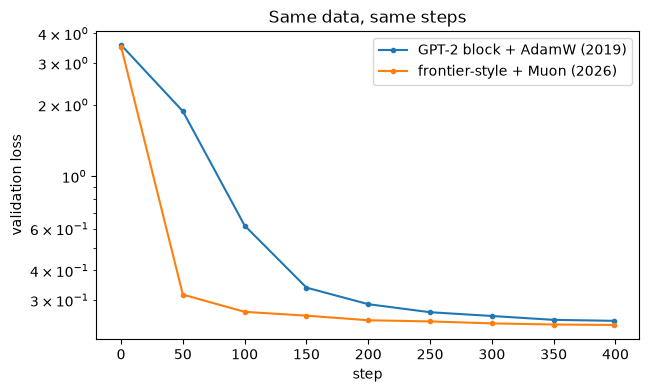

In [5]:
def newton_schulz(G, steps=5):
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G / (G.norm() + 1e-7); tr = X.shape[0] > X.shape[1]
    if tr: X = X.T
    for _ in range(steps): A = X @ X.T; X = a * X + (b * A + c * A @ A) @ X
    return X.T if tr else X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95): super().__init__(params, dict(lr=lr, momentum=momentum))
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None: continue
                buf = self.state[p].setdefault("buf", torch.zeros_like(p)); buf.mul_(g["momentum"]).add_(p.grad)
                G = p.grad + g["momentum"] * buf
                upd = torch.stack([newton_schulz(x) for x in G]) if G.ndim == 3 else newton_schulz(G)   # experts: per matrix
                p.add_(upd, alpha=-g["lr"] * max(1, p.shape[-2] / p.shape[-1]) ** 0.5)

def get_batch(src, B=32):
    ix = torch.randint(0, len(src) - CTX - 2, (B,), device=device)
    return src[ix[:, None] + torch.arange(CTX + 1, device=src.device)]

@torch.no_grad()
def val_loss(m):
    m.eval(); g = torch.Generator().manual_seed(7); out = []
    for _ in range(8):
        ix = torch.randint(0, len(val_data) - CTX - 1, (32,), generator=g).to(device)
        s = val_data[ix[:, None] + torch.arange(CTX + 1, device=val_data.device)]
        out.append(F.cross_entropy(m(s[:, :-1]).reshape(-1, V), s[:, 1:].reshape(-1)).item())
    m.train(); return float(np.mean(out))

def pretrain(m, steps=400, muon=True, mtp_w=0.3):
    hidden = [p for n, p in m.named_parameters() if p.ndim >= 2 and not n.startswith(("tok", "pos", "head"))]
    rest = [p for n, p in m.named_parameters() if not (p.ndim >= 2 and not n.startswith(("tok", "pos", "head")))]
    opts = [Muon(hidden, lr=0.02), torch.optim.AdamW(rest, lr=3e-3, betas=(0.9, 0.95), weight_decay=0.0)] if muon else \
           [torch.optim.AdamW(m.parameters(), lr=3e-3, betas=(0.9, 0.95), weight_decay=0.1)]
    base = [[g["lr"] for g in o.param_groups] for o in opts]; curve = []
    for s in range(steps):
        f = min(1, (s + 1) / 30) * 0.5 * (1 + math.cos(math.pi * s / steps))
        for o, lrs in zip(opts, base):
            for g, lr in zip(o.param_groups, lrs): g["lr"] = lr * f
        seq = get_batch(train_data); x, y = seq[:, :-1], seq[:, 1:]
        if isinstance(m, FrontierLM) and m.use_mtp and mtp_w > 0:
            main, mtp = m(x, with_mtp=True)
            loss = F.cross_entropy(main.reshape(-1, V), y.reshape(-1)) + mtp_w * F.cross_entropy(mtp.reshape(-1, V), seq[:, 2:].reshape(-1))
        else:
            loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        for o in opts: o.zero_grad()
        loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        for o in opts: o.step()
        if isinstance(m, FrontierLM):
            for moe in m.all_moes(): moe.update_bias()
        if s % 50 == 0 or s == steps - 1: curve.append((s, val_loss(m)))
    return curve

runs = {}
for name, make, muon in [("GPT-2 block + AdamW (2019)", lambda: GPT2(), False), ("frontier-style + Muon (2026)", lambda: FrontierLM(), True)]:
    seed_everything(0); m = make().to(device); t0 = time.time()
    curve = pretrain(m, muon=muon); runs[name] = (m, curve)
    print(f"{name:30s} final val loss {curve[-1][1]:.4f} | {time.time() - t0:.0f}s")
plt.figure(figsize=(7, 4))
for name, (_, c) in runs.items(): plt.plot(*zip(*c), marker=".", label=name)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("validation loss"); plt.legend(); plt.title("Same data, same steps"); plt.show()

## Did the bias-based balancing keep the experts evenly used?

In [6]:
m = runs["frontier-style + Muon (2026)"][0]
with torch.no_grad(): m(get_batch(val_data)[:, :-1])
for i, moe in enumerate(m.moes):
    share = (moe.load / moe.load.sum()).cpu().numpy()
    print(f"layer {i} ({type(m.mixers[i]).__name__:14s}) expert load: {np.round(share, 2)} | bias {np.round(moe.bias.cpu().numpy(), 2)}")

layer 0 (GatedDeltaNet ) expert load: [0.11 0.13 0.13 0.13 0.12 0.11 0.12 0.14] | bias [0.48 0.54 0.51 0.54 0.45 0.57 0.54 0.54]
layer 1 (GatedDeltaNet ) expert load: [0.14 0.16 0.12 0.1  0.11 0.13 0.13 0.11] | bias [0.42 0.54 0.45 0.42 0.39 0.36 0.3  0.45]
layer 2 (GatedDeltaNet ) expert load: [0.12 0.12 0.13 0.12 0.12 0.14 0.12 0.12] | bias [0.24 0.24 0.36 0.24 0.24 0.21 0.03 0.33]
layer 3 (GatedAttention) expert load: [0.13 0.11 0.1  0.15 0.13 0.12 0.14 0.12] | bias [0.33 0.45 0.48 0.54 0.42 0.45 0.48 0.36]


## Generation, with the MTP module as a free drafter

In [7]:
@torch.no_grad()
def generate(m, prompt, n=160, temperature=0.7):
    m.eval(); idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(n):
        p = F.softmax(m(idx[:, -CTX:])[:, -1] / temperature, -1); idx = torch.cat([idx, torch.multinomial(p, 1)], 1)
    return decode(idx[0].tolist())
print(generate(m, "The router "))

with torch.no_grad():
    seq = get_batch(val_data)[:, :-1]; h = m.hidden(seq); g1 = m.head(m.ln(h)).argmax(-1)
    h1 = m.mtp_proj(torch.cat([m.mtp_nh(h), m.mtp_ne(m.tok(g1))], -1)); h1 = h1 + m.mtp_mixer(m.mtp_n1(h1)); h1 = h1 + m.mtp_moe(m.mtp_n2(h1))
    g2 = m.head(m.ln(h1)).argmax(-1); ok = g1[:, :-1] == seq[:, 1:]
    rate = ((g2[:, :-1] == g1[:, 1:]) & ok).sum().item() / ok.sum().item()
print(f"\nMTP draft acceptance (greedy): {rate:.0%} -> about {1 + rate:.2f} tokens per forward pass with self-speculative decoding")

The router forgets the key and value once again, then the teacher routes a long context. The model remembers the next token slowly. The model copies every expert slowly. T

MTP draft acceptance (greedy): 97% -> about 1.97 tokens per forward pass with self-speculative decoding


## Where this leaves us
- The 2026 recipe is a **combination**: cheap linear-memory layers for most of the depth plus a few gated full-attention layers; sparse experts with a shared expert for capacity; MTP for denser training and faster decoding; and Muon to optimise the matrices. DeepSeek-V4 adds compressed sparse attention and mHC; Engram adds lookup memory.
- Here the frontier-style model edges out the GPT-2 block while using about a third fewer *active* parameters per token. It is slower in wall-clock time only because its recurrent layers run as a Python loop rather than a fused kernel. On this tiny corpus both approach the same loss floor, so the toy can't show the real advantages, which appear at billions of parameters and very long contexts: constant-memory long context, more capacity at the same active compute, faster decoding and stability.
- Every component is still the weighted sum + nonlinearity of 1943 (notebook 01), trained with backpropagation from 1986 (notebook 09).